# 历史受迫方腔：参考解时间收敛

保存记录中的外力是 $f=(0,\sin x)$，不是当前生产配置的 $f=(0,\sin 4\pi x)$。不得套用当前外力或稳态窗口的解释。

[中文论文描述](description.tex) · [输入与执行](README.md)

In [1]:
from pathlib import Path
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').is_file())
REPORT_DIRECTORY = Path('reports/forced_ns_convergence/20260922T032418-3cd92bd4')
EXPECTED_ANALYSIS_SHA256 = '7a4e578d962c3eb3dd5a447abc8849c6e6156da5cc668c52e515980911bb2c04'
EXPECTED_TABLE_SHA256 = 'd933c346be2a618b0d1630d98f255005010077bdf2c9321a0f1023b8334caa18'

## 输入与限制
只展示下面显式报告及其保存误差表；不选择最新运行、不推进求解器、不重算场误差。
执行时校验报告、表格、捕获批次和全部被测/参考记录，以及完成状态与观测时刻。
历史路径只按捕获的实验名和运行编号迁移到 `PROJECT_ROOT/runs/`，不搜索替代运行。
失败运行留在表内，图底部的叉号仅表示失败步长，不代表一个数值误差。
$H^1$ 列是离散黏性二次型定义的半范数，不是压力误差。

In [2]:
import sys, json, math
from html import escape
sys.path.insert(0, str(PROJECT_ROOT))
from experiments.study_data import read_reference_study
from experiments.plotting import reference_error_figure
from IPython.display import display, HTML
import matplotlib.pyplot as plt
%matplotlib inline
report = PROJECT_ROOT/REPORT_DIRECTORY
batch, physical, rows = read_reference_study(
    PROJECT_ROOT, report, analysis_sha256=EXPECTED_ANALYSIS_SHA256,
    table_sha256=EXPECTED_TABLE_SHA256)
analysis = json.loads((report/'analysis.json').read_text())
print('Captured batch:', Path(analysis['batch']).parent.name)
print('Historical solver source:', batch['source']['code_sha256'])
print('Recorded physical settings:', json.dumps({k: physical.get(k) for k in
      ('experiment', 'nx', 'ny', 'lx', 'ly', 'nu', 'gamma', 'T', 'force', 'initial_condition', 'boundary')}, ensure_ascii=False))
print('Trial runs:', len(batch['trials']), '; failed trial rows:', sum(r['status']=='failed' for r in rows))

Captured batch: 20260922T023439-35a9711f
Historical solver source: 8eaa72e89679402639674e8a5f71005e56e623aaf7dbac4ab3c7a552b9cf1622
Recorded physical settings: {"experiment": "forced_ns", "nx": 128, "ny": 128, "lx": 1.0, "ly": 1.0, "nu": 0.01, "gamma": 1.0, "T": 2.0, "force": "[0, amplitude*sin(x)]", "initial_condition": "zero", "boundary": "homogeneous_no_slip"}
Trial runs: 16 ; failed trial rows: 0


## 全步长区间
所有保存层均保留。失败或缺失误差使折线断开，不跨过失败层连线；极大但有限的误差也不删除。
灰色虚线仅为二阶斜率导线，不是对全区间的拟合或稳定性证明。

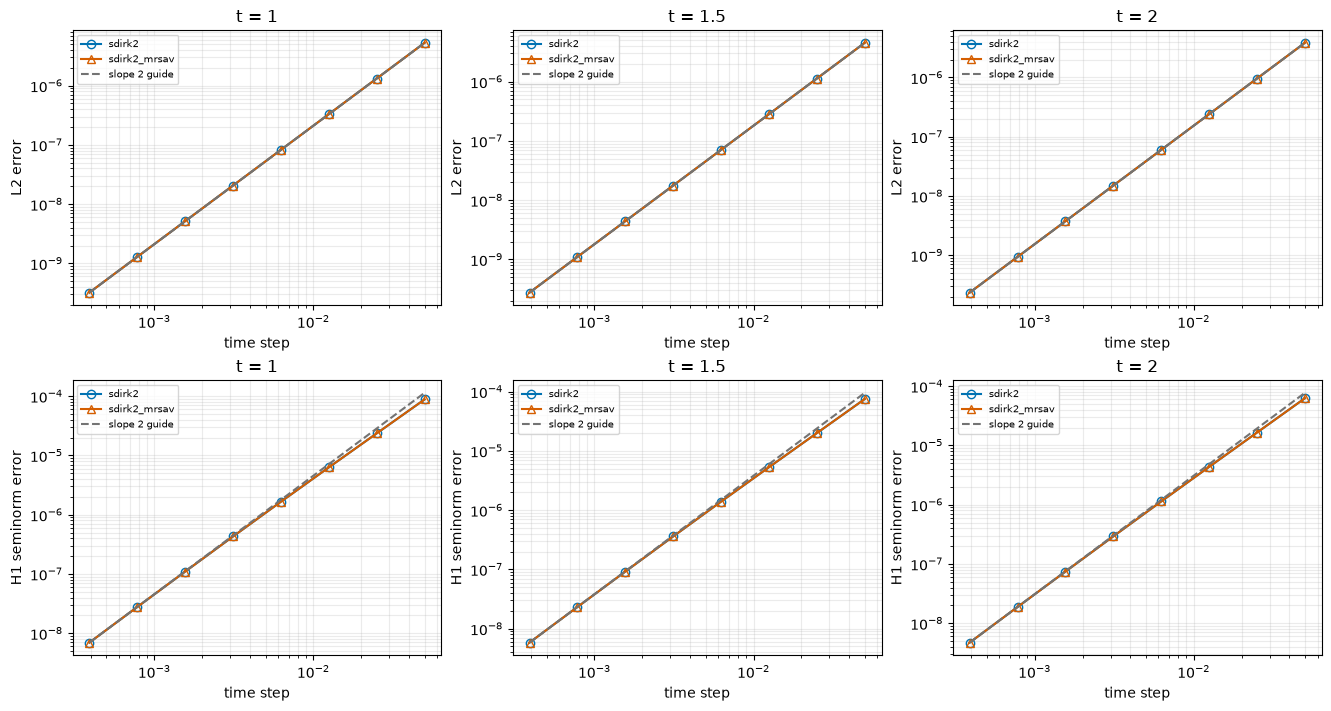

In [3]:
figure = reference_error_figure(rows)
display(figure)
plt.close(figure)

## 细步长放大（$k\geq6$）
固定展示后三个整数层的局部形态，不替代全区间图，也不把这一区间的阶数推广到粗步长。

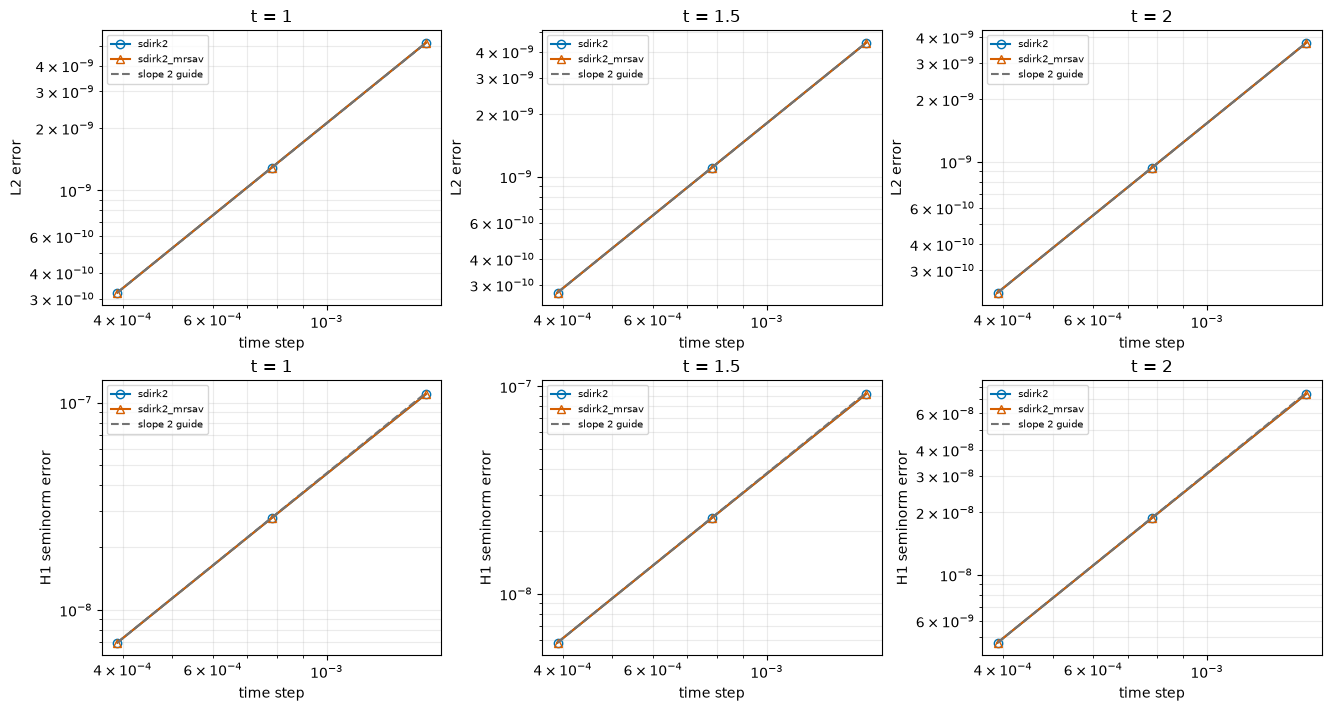

In [4]:
fine_rows = [row for row in rows if float(row['k']) >= 6]
if fine_rows:
    figure = reference_error_figure(fine_rows)
    display(figure)
    plt.close(figure)

## 完整保存误差与观察阶
`NaN` 原样保留；`failed` 不作为有限误差点绘制。观察阶来自保存表，只有相邻层误差有效时才有数值。
图中的局部阶数不能替代参考充分性或空间收敛验证。

In [5]:
columns = ('time', 'k', 'dt', 'scheme', 'status', 'L2', 'H1', 'L2_rate', 'H1_rate')
def format_cell(row, key):
    value = row[key]
    if key in ('L2', 'H1', 'dt'):
        number = float(value)
        return f'{number:.3e}' if math.isfinite(number) else 'NaN'
    return escape(str(value))
body = ''.join('<tr>'+''.join('<td>'+format_cell(row, key)+'</td>' for key in columns)+'</tr>' for row in rows)
display(HTML('<table><thead><tr>'+''.join('<th>'+key+'</th>' for key in columns)+'</tr></thead><tbody>'+body+'</tbody></table>'))

time,k,dt,scheme,status,L2,H1,L2_rate,H1_rate
1.0,1,5.000e-02,sdirk2,complete,5.275e-06,8.822e-05,nan,nan
1.0,2,2.500e-02,sdirk2,complete,1.318e-06,2.358e-05,2.001176194895723,1.903886431885864
1.0,3,1.250e-02,sdirk2,complete,3.295e-07,6.291e-06,1.9998403180206308,1.90583989285521
1.0,4,6.250e-03,sdirk2,complete,8.239e-08,1.658e-06,1.9995198424013652,1.9238982018309527
1.0,5,3.125e-03,sdirk2,complete,2.060e-08,4.296e-07,1.9996077358929736,1.9483912333606561
1.0,6,1.563e-03,sdirk2,complete,5.151e-09,1.097e-07,1.9998748127890118,1.9693838317768317
1.0,7,7.813e-04,sdirk2,complete,1.287e-09,2.773e-08,2.0004668753561132,1.9839058764879531
1.0,8,3.906e-04,sdirk2,complete,3.213e-10,6.960e-09,2.002332353649051,1.9945463741690272
1.0,1,5.000e-02,sdirk2_mrsav,complete,5.275e-06,8.822e-05,nan,nan
1.0,2,2.500e-02,sdirk2_mrsav,complete,1.318e-06,2.358e-05,2.0011761942937625,1.9038864299879117


## 保存的参考敏感性检查
共同 SDIRK2 参考与再细一层参考的差，除以同一观测时刻/范数下最小有效被测误差。
所有项须不超过批次指定阈值；通过仅表示这次细化对的敏感性检查通过，不是严格误差上界。
本展示核对保存输入完整性并呈现原检查，不独立从场数据重算误差。

In [6]:
print('Reference level:', batch['references']['reference_k'])
print('Sensitivity threshold:', batch['config']['sensitivity_threshold'])
display(HTML('<pre>'+escape(json.dumps(analysis['reference_checks'], indent=2))+'</pre>'))

Reference level: 12
Sensitivity threshold: 0.05
